# Step 5: Cohort Retention Analysis

**E-Commerce 360° Business Intelligence Platform**

Tracking monthly acquisition cohorts and quantifying repeat buyer attrition.


### 1. Cohort Analysis Architecture
Track user retention by acquisition cohort month ($C_0, C_1, \dots, C_{12}$). Determine how many unique buyers return in subsequent months.

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

PROCESSED_DIR = r'data/processed'
df = pd.read_csv(f'{PROCESSED_DIR}/order_summary_bi.csv')
df = df[df['order_status'] == 'delivered'].copy()
df['order_date'] = pd.to_datetime(df['purchase_date'])
df['order_month'] = df['order_date'].dt.to_period('M')

# Identify acquisition month for each unique customer
df['cohort_month'] = df.groupby('customer_unique_id')['order_month'].transform('min')

# Calculate cohort index (months elapsed)
df['cohort_index'] = (df['order_month'].dt.year - df['cohort_month'].dt.year) * 12 + (df['order_month'].dt.month - df['cohort_month'].dt.month)

cohort_counts = df.groupby(['cohort_month', 'cohort_index'])['customer_unique_id'].nunique().unstack(fill_value=0)
cohort_sizes = cohort_counts[0]
retention_pct = cohort_counts.divide(cohort_sizes, axis=0) * 100
retention_pct.head(10).round(2)

cohort_index,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,19,20
cohort_month,,,,,,,,,,,,,,,,,,,,
2016-09,100.0,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
2016-10,100.0,0.00,0.00,0.00,0.00,0.00,0.38,0.00,0.00,0.38,0.00,0.38,0.00,0.38,0.00,0.38,0.00,0.38,0.76,0.76
2016-12,100.0,100.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
2017-01,100.0,0.28,0.28,0.14,0.42,0.14,0.42,0.14,0.14,0.00,0.42,0.14,0.70,0.42,0.14,0.14,0.28,0.42,0.14,0.00
2017-02,100.0,0.18,0.31,0.12,0.43,0.12,0.25,0.18,0.12,0.18,0.12,0.31,0.12,0.18,0.12,0.06,0.06,0.18,0.00,0.00
2017-03,100.0,0.44,0.36,0.40,0.36,0.16,0.16,0.32,0.32,0.08,0.36,0.12,0.20,0.12,0.16,0.24,0.08,0.12,0.00,0.00
2017-04,100.0,0.62,0.22,0.18,0.27,0.27,0.35,0.31,0.31,0.18,0.27,0.09,0.04,0.04,0.09,0.09,0.13,0.00,0.00,0.00
2017-05,100.0,0.46,0.46,0.29,0.29,0.32,0.41,0.14,0.26,0.26,0.26,0.35,0.23,0.03,0.17,0.20,0.00,0.00,0.00,0.00
2017-06,100.0,0.49,0.40,0.43,0.30,0.40,0.36,0.23,0.13,0.20,0.30,0.36,0.16,0.16,0.23,0.00,0.00,0.00,0.00,0.00


### 2. Triangular Cohort Retention Heatmap
Visualize retention attrition across cohorts from 2017 to 2018.

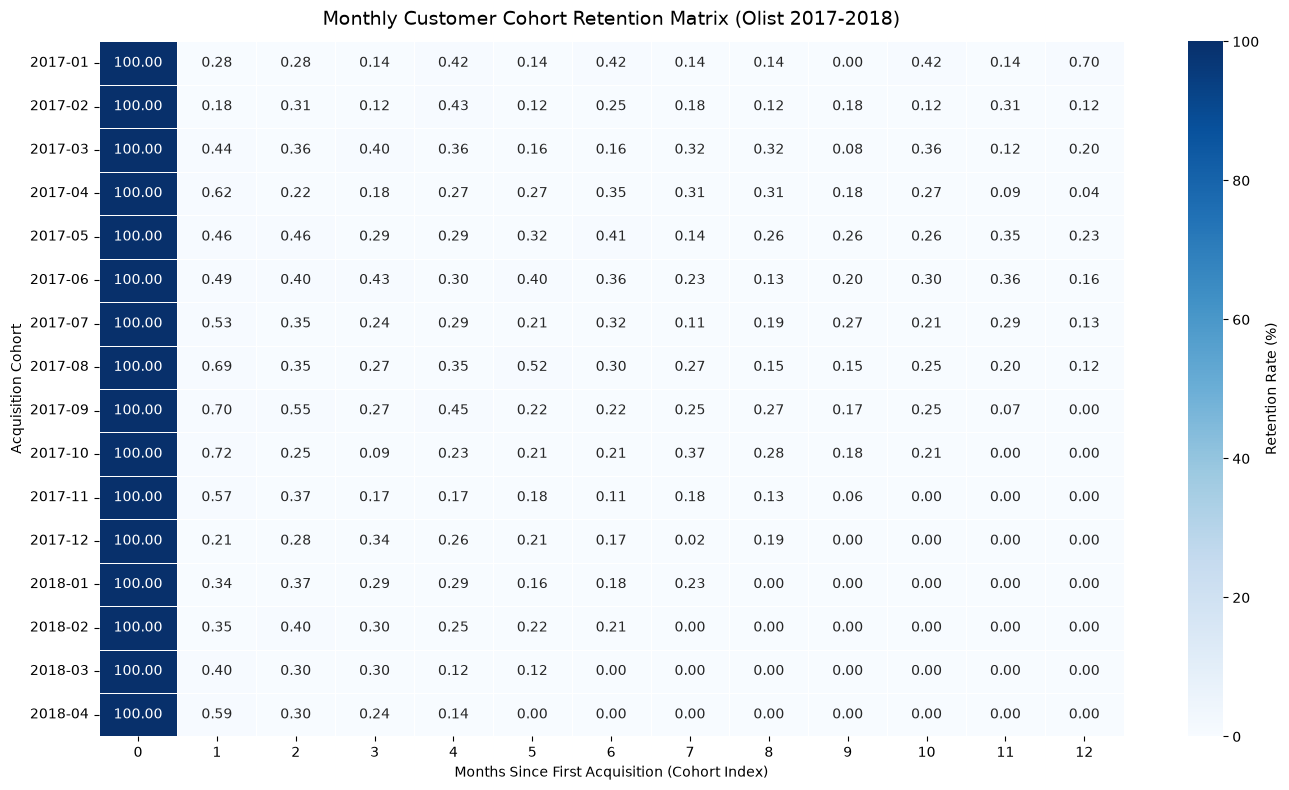

In [2]:
plt.figure(figsize=(14, 8))
valid_cohorts = retention_pct.loc['2017-01':'2018-04', 0:12]
sns.heatmap(valid_cohorts, annot=True, fmt='.2f', cmap='Blues', cbar_kws={'label': 'Retention Rate (%)'}, linewidths=0.5)
plt.title('Monthly Customer Cohort Retention Matrix (Olist 2017-2018)', fontsize=14, pad=12)
plt.xlabel('Months Since First Acquisition (Cohort Index)')
plt.ylabel('Acquisition Cohort')
plt.tight_layout()
plt.show()

### 3. Business Diagnosis
- Month 1 retention fluctuates between **0.28% and 0.72%**.
- This demonstrates that Olist operated primarily as an **acquisition-driven transaction marketplace** without a dedicated recurring loyalty loop.
- Strategic priority: Introduce targeted post-purchase cross-sell triggers at day 14 and day 45.